# Test 2 de modélisation numérique - semaine 14

### Instructions:

- L'examen dure 2 h 30.
- Ce document contient une figure qui devrait s'afficher dans le notebook (pour cela, assurez-vous d'avoir copié-collé également le répertoire 'fig' de 'Données Examen').
- Vous pouvez vous référer à au document 'Introduction à Python pour le cours de modélisation numérique' disponible dans le répertoire 'Données Examen'.
- Assurez-vous d'exécuter l'intégralité de votre script pour garantir son bon fonctionnement.
- À la fin du test, rendez votre fichier `Nom_Prenom_test2.ipynb` en le déposant dans le sous-dossier à votre nom, dans le dossier de votre salle, dans le dossier `Dépôt Copies`:

```bash
`Dépot copies"
├── env-2113
│   ├── Nom1
│   ├── Nom2
|   -...
├── env-2138
│   ├── Nom1
│   ├── Nom2
|   -...
├── env-2145
│   ├── Nom1
│   ├── Nom2
|   -...
├── env-2153
│   ├── Nom1
│   ├── Nom2
|   -...
├── geo-2145
│   ├── Nom1
│   ├── Nom2
|   -...
```



Le but de l'exercice est de modéliser l'évolution de la température de la croûte terrestre en deux dimensions, en supposant que celle-ci est composée de deux plaques tectoniques de 30 km et 20 km d'épaisseur, empilées l'une sur l'autre et se déplaçant horizontalement dans deux directions opposées. Le domaine modélisé a une longueur de 100 km et une profondeur de 50 km (voir Figure ci-dessous). L'évolution du champ 2D de température $T=T(x,z)$ est le résultat de la diffusion thermique le long des axes $x$ et $z$, ainsi que de l'advection due au déplacement des plaques, $V_x$, le long d'une seule dimension $x$ :

\begin{equation}
\frac{\partial T}{\partial t} + \frac{\partial q_x}{\partial x} + \frac{\partial q_z}{\partial z}  +V_x \frac{\partial T}{\partial x}\ = 0   , \qquad (1)
\end{equation}

\begin{equation} 
q_x = - D \frac{\partial T}{\partial x} \: ; \: \: q_z = - D \frac{\partial T}{\partial z}, \qquad (2)
\end{equation}
  
où $D$ est un paramètre constant de diffusivité (ou conductivité) de la température, $V_x$ est la vitesse d'advection, qui vaut 10 cm par an sur la plaque supérieure et -10 cm par an sur la plaque inférieure. La température initiale est de 500°C sur tout le domaine (si cette condition initiale n'est pas réaliste, la température s'ajustera rapidement à des valeurs réalistes.) Les conditions aux bords (maintenues durant toute la simulation) sont les suivantes :

- La température à la surface (z = 50 km) est maintenue à 0°C.  
- La température à la base du domaine (z = 0 km) est maintenue à 1000°C.  
- La température à gauche de la plaque supérieure est maintenue à la valeur initiale moins 100°C.  
- Nous supposons un flux de température nul à droite de la plaque supérieure.  
- La température à droite de la plaque inférieure est maintenue à la valeur initiale plus 100°C.  
- Nous supposons un flux de température nul à gauche de la plaque inférieure.  
 
<div style="text-align: center;">
    <img src="fig/scheme0.png" style="width: 60%;">
    <p><strong>Figure :</strong> Le but de l'exercice est de modéliser le géotherme de la croûte terrestre.</p>
</div>
 
Pour que le modèle soit numériquement stable, le pas de temps est calculé avec la formule suivante : 
\begin{equation}
dt = \min \left\{ \frac{\min(dx,dz)^2}{4.1 \times D},  \frac{0.01 \times dx}{\max (|V_x|)} \right\} \qquad (3)
\end{equation}
où $dx$ et $dz$ sont les pas de discrétisation en $x$ et $z$. Tous les paramètres sont donnés dans la table ci-dessous.

# Q1: Modèle de base

Implémentez le modèle et faites en sorte qu'il s'arrête lorsque la moyenne des valeurs absolues de la différence entre deux solutions successives soit inférieure à $10^{-4}$. Assurez-vous que votre code affiche l'évolution de la température en 2D au cours du temps dans une figure bien illustrée. Pour cela, vous pouvez utiliser les lignes suivantes pour intialiser une figure et sa colorbar :

```python
fig, ax = plt.subplots()
s = ax.imshow(T, extent=[0, Lx, 0, Lz], origin='lower', cmap='jet',vmin=0,vmax=1000)
cbar = plt.colorbar(s)        
```
ainsi que pour la mettre à jour dans la boucle temporelle avec :

```python
clear_output(wait=True)
ax.cla() 
ax.imshow(T, extent=[0, Lx, 0, Lz], origin='lower', cmap='jet',vmin=0,vmax=1000)
... # à completer
display(fig)
```
 
# Q2: Modèle élaboré

Pour la question 2, nous allons apporter au code précédent une modification. Pour cela, nous introduirons un paramètre $Q$ défini par 1 ou 2, afin que le code fonctionne pour la question 1 ou 2 en changeant simplement la valeur de $Q$. La modification à apporter à la version originale est la suivante. Au lieu de supposer que la diffusivité de la température est constante, nous supposons qu'elle dépend de la température et est définie par la loi suivante : 
\begin{equation}
D(T) = 300 \times \exp(-0.005 \times (T-15)), \qquad (4)
\end{equation}
ce qui rend l'équation de diffusion non linéaire, et nous oblige ainsi à mettre à jour $D$ et le pas de temps dans la boucle du modèle numérique. Attention à adapter la définition du pas de temps, car $D$ étant maintenant une matrice, il faut donc prendre le maximum de $D$. De plus, $D$ est maintenant une matrice (non plus une seule valeur), il faut faire en sorte que sa taille soit compatible pour multiplier les flux en x and z.
 
 
| **Paramètres**                                   | **Valeurs**                  | **Nom en Python**  |
|--------------------------------------------------|------------------------------|---------------------|
| Numéro de la question                            | 1 ou 2                       | `Q`                 |
| Longueur du domaine                              | 100 km                       | `Lx`                |
| Hauteur du domaine                               | 50 km                        | `Lz`                |
| Nombre de cellules en x                          | 70                           | `nx`                |
| Nombre de cellules en z                          | 90                           | `nz`                |
| Temps total maximal                              | 3 Ma                         | `tmax`              |
| Vitesse horizontale plaque supérieure $V_x$      | 10 cm/a                      | `Vx`                |
| Vitesse horizontale plaque inférieure $V_x$      | -10 cm/a                     | `Vx`                |
| Température initiale                             | 500°C                        | `Ti`                |
| Température à la base                            | 1000°C                       | `Tb`                |
| Température à la surface                         | 0°C                          | `Ts`                |
| Diffusivité $D$ de la température (Q=1)          | 300 $km^2/Ma$                | `D`                 |
| Diffusivité $D$ de la température (Q=2)          | Equation (4)                 | `D`                 | 
| Tolerance sortie du modele                       | $10^{-4}$                    | `tol`               | 

### ✅ **À vous de faire !** 

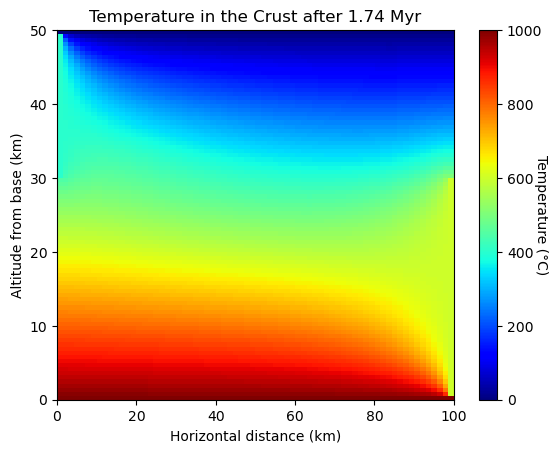

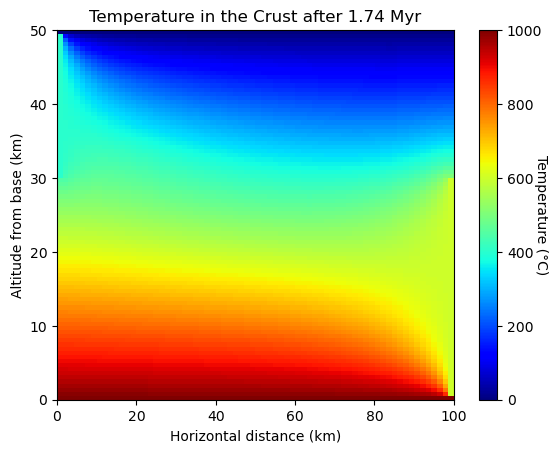

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, clear_output

Q=1

# Physics
D = 300.0       # diffusivity, km^2/Myr
Lx = 100.0      # length along x, km
Lz = 50.0       # depth along y, km
ex_t =  100.0   # speed tecto top, km/Myr 
ex_b = -100.0   # speed tecto bot, km/Myr 
Ts = 0.0        # surface temperature, C
Tb = 1000.0     # base temperature, C
Ti = 500.0      # initial temperature, C
tmax = 3.0      # maximum time, Myr 
tol  = 10**(-4) # seuil d'arret

# Numerics
nx = 70  # number of x cells
nz = 90  # number of z cells
dx = Lx / (nx - 1)  # size of x-cell
dz = Lz / (nz - 1)  # size of z-cell
x = np.linspace(0, Lx, nx)  # x-coordinates
z = np.linspace(0, Lz, nz)  # z-coordinates 
nout =  1000  # frequency of plotting

# Initialization
T = np.ones((nz, nx))*Ti       # array for temperature
dTdt = np.zeros((nz, nx))    # array for change of T
Vx = np.zeros((nz, nx-1))  # array for velocity

Vx[:int(3*nz/5),:] = ex_b  
Vx[int(3*nz/5):,:] = ex_t 

time = 0.0     # initial time
it = 0         # initial timestep 
 
fig, ax = plt.subplots()
s = ax.imshow(T, extent=[0, Lx, 0, Lz], origin='lower', cmap='jet',vmin=0,vmax=1000)
cbar = plt.colorbar(s)
 
# Time loop
while time < tmax:
    
    T_old = np.copy(T)
    
    # diffusion
    if Q==1:
        qz = -D * (T[1:, 1:-1] - T[:-1, 1:-1]) / dz  
        qx = -D * (T[1:-1, 1:] - T[1:-1, :-1]) / dx 
    else:
        D =  300 *np.exp(-0.005*(T-15))
        qz = - 0.5 * (D[1:,1:-1]+D[:-1,1:-1]) * (T[1:, 1:-1] - T[:-1, 1:-1]) / dz  
        qx = - 0.5 * (D[1:-1,1:]+D[1:-1,:-1]) * (T[1:-1, 1:] - T[1:-1, :-1]) / dx  
    
    # time step
    dt = min(min(dx, dz) ** 2 / np.max(D) / 4.1, dx / 100 / max(abs(Vx.flatten())))
 
    dTdtd = -((qx[:, 1:] - qx[:, :-1]) / dx + (qz[1:, :] - qz[:-1, :]) / dz)  # diffusion
    T[1:-1, 1:-1] += dTdtd * dt  # update rule
    
    # advection
    dTdta         = np.zeros_like(T)
    dTdta[:,:-1] -= (Vx < 0) * Vx * (T[:, 1:] - T[:, :-1]) / dx  # negative Vx
    dTdta[:,1:]  -= (Vx > 0) * Vx * (T[:, 1:] - T[:, :-1]) / dx  # positive Vx 
    T            += dt * dTdta                               # mise a jour de la advection
  
    # Set boundary conditions left
    T[:int(3*nz/5), 0] = T[:int(3*nz/5), 1] # lower, zero flux
    T[int(3*nz/5):, 0] = Ti - 100 # upper, prescribed

    # Set boundary conditions right    
    T[:int(3*nz/5),-1] = Ti + 100 # lower, prescribed
    T[int(3*nz/5):,-1] = T[int(3*nz/5):,-2] # upper, zero flux
    
    # Set boundary conditions surface
    T[-1,:] = Ts
    T[0,:]  = Tb 

    it   += 1
    time += dt
    
    # stopping criterion
    val = np.mean(np.abs(T-T_old))
    if val<tol:
        break
 
    if it % nout == 0:

        clear_output(wait=True)
        ax.cla() 
        ax.imshow(T, extent=[0, Lx, 0, Lz], origin='lower', cmap='jet',vmin=0,vmax=1000)
        plt.gca().set_aspect("auto") 
        cbar.set_label("Temperature (°C)", rotation=270)
        ax.set_xlabel('Horizontal distance (km)')
        ax.set_ylabel('Altitude from base (km)')
        ax.set_title(f'Temperature in the Crust after {round(time, 2)} Myr')
        display(fig)
        
  